In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features import build_features, CATEGORICAL_FEATURES
from src.monitoring import psi_numeric, psi_categorical, psi_label

splits = {
    "train": pd.read_parquet("../data/processed/train.parquet"),
    "valid": pd.read_parquet("../data/processed/valid.parquet"),
    "test": pd.read_parquet("../data/processed/test.parquet"),
}

model = joblib.load("../models/lightgbm_v2_calibrated.joblib")

features = {}
for name, df in splits.items():
    X = df.drop(columns=["target"])
    df["predicted"] = model.predict_proba(X)[:, 1]
    features[name] = build_features(X.copy()).reset_index(drop=True)
    features[name]["predicted"] = df["predicted"].values

KEY_NUMERIC = [
    "fico_avg", "dti", "annual_inc", "loan_amnt", "loan_to_income",
    "revol_util", "acc_open_past_24mths", "credit_history_months",
]
print({name: len(df) for name, df in splits.items()})

{'train': 335558, 'valid': 120790, 'test': 162236}


In [2]:
rows = []

for col in KEY_NUMERIC + ["predicted"]:
    rows.append({
        "feature": col,
        "type": "numeric",
        "valid_vs_train": psi_numeric(features["train"][col], features["valid"][col]),
        "test_vs_train": psi_numeric(features["train"][col], features["test"][col]),
    })

for col in CATEGORICAL_FEATURES:
    rows.append({
        "feature": col,
        "type": "category",
        "valid_vs_train": psi_categorical(features["train"][col], features["valid"][col]),
        "test_vs_train": psi_categorical(features["train"][col], features["test"][col]),
    })

psi_table = pd.DataFrame(rows).set_index("feature")
psi_table["status_test"] = psi_table["test_vs_train"].apply(psi_label)
psi_table.sort_values("test_vs_train", ascending=False).round(3)

,type,valid_vs_train,test_vs_train,status_test
feature,,,,
acc_open_past_24mths,numeric,0.760,0.761,Act
verification_status,category,0.060,0.106,Watch
addr_state,category,0.009,0.049,Stable
dti,numeric,0.042,0.042,Stable
purpose,category,0.031,0.032,Stable
revol_util,numeric,0.007,0.026,Stable
credit_history_months,numeric,0.014,0.024,Stable
loan_amnt,numeric,0.007,0.013,Stable
annual_inc,numeric,0.002,0.009,Stable


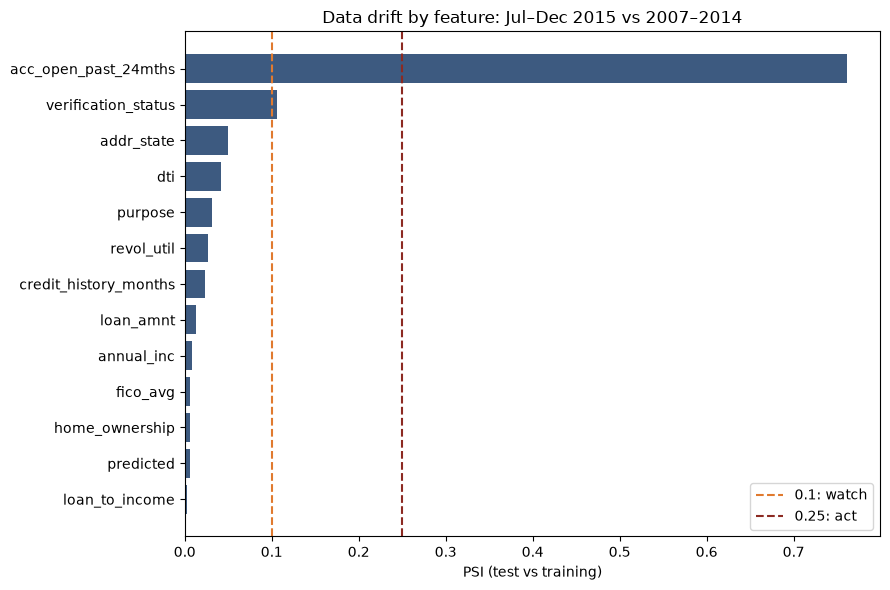

In [3]:
plot = psi_table.sort_values("test_vs_train")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot.index, plot["test_vs_train"], color="#3D5A80")
ax.axvline(0.1, color="#E07A2F", linestyle="--", label="0.1: watch")
ax.axvline(0.25, color="#8C2A22", linestyle="--", label="0.25: act")
ax.set_xlabel("PSI (test vs training)")
ax.set_title("Data drift by feature: Jul–Dec 2015 vs 2007–2014")
ax.legend()

plt.tight_layout()
plt.savefig("../results/figures/psi_by_feature.png", dpi=120)
plt.show()

In [4]:
recent = pd.concat([splits["valid"], splits["test"]]).reset_index(drop=True)
recent_features = pd.concat([features["valid"], features["test"]]).reset_index(drop=True)
recent["month"] = recent["issue_date"].dt.to_period("M")

monthly = []
for month in sorted(recent["month"].unique()):
    mask = (recent["month"] == month).values
    row = {
        "month": str(month),
        "loans": int(mask.sum()),
        "avg_predicted_pct": recent.loc[mask, "predicted"].mean() * 100,
        "actual_pct": recent.loc[mask, "target"].mean() * 100,
    }
    for col in ["predicted", "fico_avg", "dti", "loan_to_income"]:
        row[f"psi_{col}"] = psi_numeric(features["train"][col], recent_features.loc[mask, col])
    monthly.append(row)

monthly = pd.DataFrame(monthly).set_index("month")
monthly["gap_pct"] = monthly["avg_predicted_pct"] - monthly["actual_pct"]
monthly.round(3)

,loans,avg_predicted_pct,actual_pct,psi_predicted,psi_fico_avg,psi_dti,psi_loan_to_income,gap_pct
month,,,,,,,,
2015-01,23631,15.231,14.879,0.015,0.032,0.044,0.003,0.352
2015-02,16023,15.073,14.167,0.012,0.021,0.039,0.009,0.905
2015-03,16914,15.224,15.401,0.014,0.026,0.051,0.005,-0.177
2015-04,23619,15.132,15.538,0.011,0.020,0.041,0.002,-0.406
2015-05,21539,15.079,15.228,0.012,0.017,0.039,0.003,-0.149
2015-06,19064,15.004,15.359,0.011,0.013,0.039,0.004,-0.355
2015-07,30864,14.815,14.619,0.009,0.008,0.056,0.002,0.196
2015-08,23938,14.536,14.245,0.004,0.008,0.027,0.004,0.291
2015-09,18765,14.620,14.937,0.007,0.005,0.039,0.003,-0.318


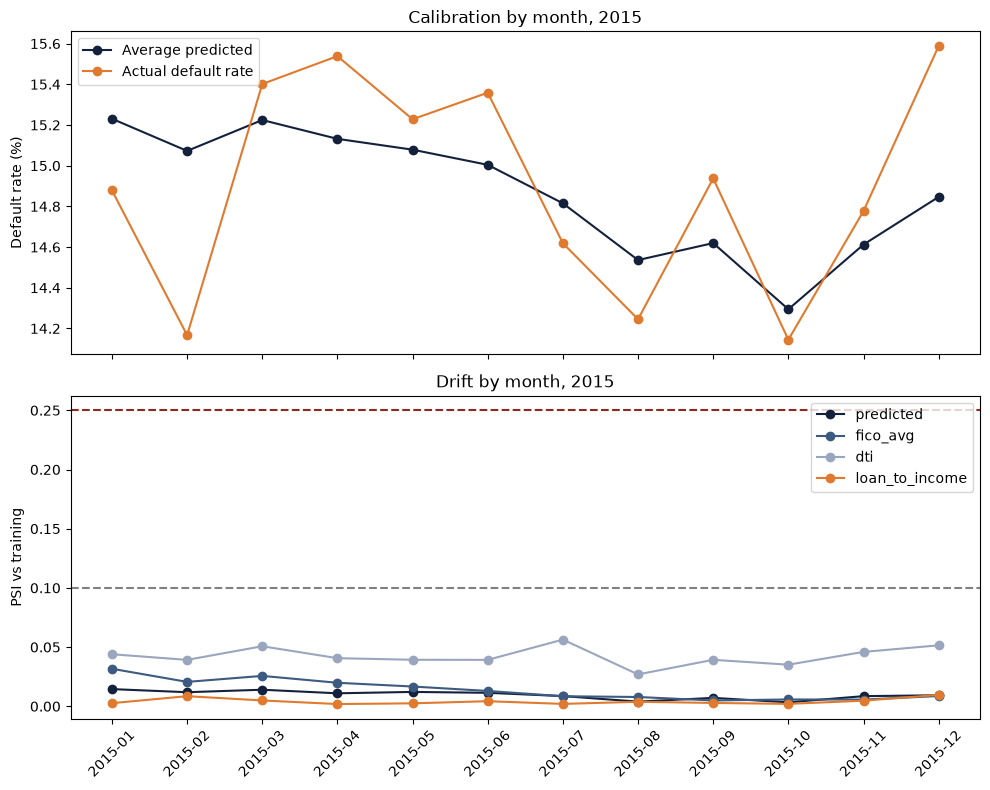

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(monthly.index, monthly["avg_predicted_pct"], marker="o", label="Average predicted", color="#14213D")
ax1.plot(monthly.index, monthly["actual_pct"], marker="o", label="Actual default rate", color="#E07A2F")
ax1.set_ylabel("Default rate (%)")
ax1.set_title("Calibration by month, 2015")
ax1.legend()

for col, color in [("psi_predicted", "#14213D"), ("psi_fico_avg", "#3D5A80"),
                   ("psi_dti", "#9AA6BD"), ("psi_loan_to_income", "#E07A2F")]:
    ax2.plot(monthly.index, monthly[col], marker="o", label=col.replace("psi_", ""), color=color)
ax2.axhline(0.1, color="gray", linestyle="--")
ax2.axhline(0.25, color="#8C2A22", linestyle="--")
ax2.set_ylabel("PSI vs training")
ax2.set_title("Drift by month, 2015")
ax2.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../results/figures/drift_by_month.png", dpi=120)
plt.show()

In [6]:
psi_table.round(4).to_csv("../results/psi_by_feature.csv")
monthly.round(4).to_csv("../results/psi_by_month.csv")
print("Saved.")

Saved.


In [7]:
train = splits["train"]
by_year = train.groupby(train["issue_date"].dt.year)["acc_open_past_24mths"].apply(
    lambda s: s.isna().mean() * 100
)
print("Missing % by issue year (training):")
print(by_year.round(1))

recent_train = features["train"][(train["issue_date"].dt.year >= 2013).values]
col = "acc_open_past_24mths"
print("\nPSI, missing values removed:",
      round(psi_numeric(features["train"][col].dropna(), features["test"][col].dropna()), 3))
print("PSI, test vs 2013-2014 only:",
      round(psi_numeric(recent_train[col], features["test"][col]), 3))

Missing % by issue year (training):
issue_date
2007    100.0
2008    100.0
2009    100.0
2010    100.0
2011    100.0
2012     13.9
2013      0.0
2014      0.0
Name: acc_open_past_24mths, dtype: float64

PSI, missing values removed: 0.024
PSI, test vs 2013-2014 only: 0.02
